# Módulo 4: Aprendizaje Automático (Machine Learning)
## Semana 2 - Clase 5: Taller Comparativo de Clasificadores

En la clase anterior utilizamos **Regresión Logística** para predecir categorías. Sin embargo, en la Inteligencia Artificial existe el teorema del *"No Free Lunch"* (No hay almuerzo gratis), que dicta que **ningún algoritmo es perfecto para todos los problemas**.

Hoy realizaremos un **Taller Comparativo** paso a paso. Usaremos un dataset químico de **Vinos** y enfrentaremos a 3 algoritmos con filosofías radicalmente distintas para ver cómo "piensan" y cómo toman decisiones:

1. **k-Nearest Neighbors (k-NN):** Filosofía basada en Similitud y Distancia (Geometría).
2. **Árboles de Decisión:** Filosofía basada en Reglas Lógicas (If-Then).
3. **Naive Bayes:** Filosofía basada en Probabilidad Teórica.

---
## **Paso 1: Extracción y Exploración de Datos**

Utilizaremos el famoso dataset *Wine Quality* incluido en `scikit-learn`. El objetivo es predecir de qué **cultivo (Clase 0, 1 o 2)** proviene un vino basándonos en sus componentes químicos.

### Diccionario de Datos (Traducción al Español)
Dado que las bases de datos originales están en inglés, aquí detallamos el propósito de cada columna para entender la química del vino:
- **Alcohol:** Grado alcohólico del vino.
- **Acido_Malico (Malic Acid):** Un ácido natural del vino que da sabor agrio.
- **Ceniza (Ash):** Cantidad de material inorgánico restante tras la evaporación.
- **Alcalinidad_Ceniza (Alcalinity of Ash):** Medida de qué tan alcalina es la ceniza.
- **Magnesio (Magnesium):** Mineral presente en el vino.
- **Fenoles_Totales (Total Phenols):** Compuestos químicos que afectan el sabor y color.
- **Flavonoides (Flavanoids):** Antioxidantes naturales en la uva.
- **Fenoles_No_Flavonoides:** Otro tipo de compuesto aromático.
- **Proantocianidinas:** Taninos que dan estructura y astringencia al vino.
- **Intensidad_Color:** Qué tan oscuro es el vino.
- **Matiz (Hue):** Tonalidad del color del vino.
- **OD280_OD315:** Medida de dilución del vino (prueba de pureza de proteínas).
- **Prolina (Proline):** Un aminoácido principal presente en la uva.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ocultar advertencias para una clase más limpia
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_wine

datos_vino = load_wine()
X = pd.DataFrame(datos_vino.data, columns=datos_vino.feature_names)
y = pd.Series(datos_vino.target, name="Clase_de_Vino")

# Mapeo para traducir las columnas al español y facilitar la comprensión
mapeo_columnas = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Acido_Malico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad_Ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles_Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles_No_Flavonoides',
    'proanthocyanins': 'Proantocianidinas',
    'color_intensity': 'Intensidad_Color',
    'hue': 'Matiz',
    'od280/od315_of_diluted_wines': 'OD280_OD315',
    'proline': 'Prolina'
}

X.rename(columns=mapeo_columnas, inplace=True)
print("Datos cargados y columnas traducidas al español exitosamente.")

Datos cargados y columnas traducidas al español exitosamente.


Veamos los primeros 5 registros para comprobar la traducción y los datos.

In [2]:
display(X.head())

,Alcohol,Acido_Malico,Ceniza,Alcalinidad_Ceniza,Magnesio,Fenoles_Totales,Flavonoides,Fenoles_No_Flavonoides,Proantocianidinas,Intensidad_Color,Matiz,OD280_OD315,Prolina
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Ahora veamos cómo están distribuidas las clases (lo que queremos predecir). ¿Están balanceadas?

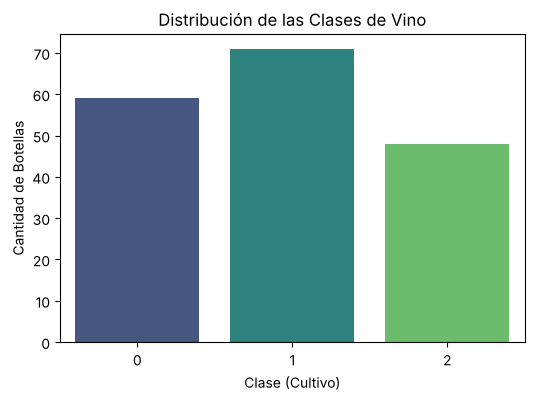

In [3]:
plt.figure(figsize=(6,4))
sns.countplot(x=y, palette='viridis')
plt.title('Distribución de las Clases de Vino')
plt.xlabel('Clase (Cultivo)')
plt.ylabel('Cantidad de Botellas')
plt.show()

---
## **Paso 2: Separación de Datos (Train/Test Split)**

Como siempre, debemos ocultarle una parte de los datos a nuestros algoritmos para poder examinarlos al final de la clase.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
print(f"Datos para entrenar (aprender): {X_train.shape[0]} botellas.")
print(f"Datos para evaluar (examen): {X_test.shape[0]} botellas.")

Datos para entrenar (aprender): 124 botellas.
Datos para evaluar (examen): 54 botellas.


---
## **Paso 3: Modelo 1 - k-Nearest Neighbors (k-NN)**

**Filosofía:** "Dime con quién andas y te diré quién eres".
El algoritmo de los $k$ vecinos más cercanos no calcula fórmulas. Cuando llega un vino nuevo, simplemente mide la distancia geométrica hacia los otros vinos. Si le decimos que $k=5$, buscará los 5 vinos más parecidos y hará una votación.

**EL PELIGRO:** Como usa distancias matemáticas, las columnas con números grandes arruinarán el cálculo frente a columnas con números pequeños.

**Demostración del problema:** Observemos el tamaño de los números en nuestros datos crudos.

In [5]:
print("Valores máximos sin escalar:")
display(X_train[['Alcohol', 'Magnesio', 'Prolina']].max())

Valores máximos sin escalar:


Alcohol       14.83
Magnesio     162.00
Prolina     1515.00
dtype: float64

¡La Prolina llega a más de 1600 mientras el Alcohol apenas a 14! k-NN creerá falsamente que la Prolina es más importante.
**Solución Obligatoria:** Estandarizar (Escalar) los datos.

In [6]:
from sklearn.preprocessing import StandardScaler

# 1. Instanciamos el escalador
scaler = StandardScaler()

# 2. Escalamos los datos de entrenamiento y de prueba
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

print("¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.")

¡Datos escalados exitosamente! Ahora todas las columnas tienen la misma importancia geométrica.


Ahora sí, entrenemos a nuestro clasificador k-NN y veamos qué tan exacto es.

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# 3. Instanciar y Entrenar
knn = KNeighborsClassifier(n_neighbors=5) # Elegimos buscar a los 5 vecinos más cercanos
knn.fit(X_train_esc, y_train)

# 4. Predecir y Evaluar
pred_knn = knn.predict(X_test_esc)
acc_knn = accuracy_score(y_test, pred_knn)
print(f"Exactitud de k-NN: {acc_knn * 100:.2f}%")

Exactitud de k-NN: 94.44%


---
## **Paso 4: Modelo 2 - Árboles de Decisión**

**Filosofía:** El juego de "Adivina Quién?".
Un Árbol de Decisión no usa distancias, usa **reglas lógicas**. Buscará la columna química que mejor parta los datos en grupos puros (bajando la *Entropía* o impureza de *Gini*).

*Nota Docente: ¡Los árboles NO necesitan que escalemos los datos! A una regla If-Then no le importa el tamaño del número.*

In [8]:
from sklearn.tree import DecisionTreeClassifier

# 1. Instanciar y Entrenar
# max_depth=3 significa que solo le permitiremos hacer 3 niveles de preguntas para evitar que se "memorice" los datos (Overfitting)
arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_train, y_train) # Usamos los datos originales (en español) sin escalar

# 2. Predecir y Evaluar
pred_arbol = arbol.predict(X_test)
acc_arbol = accuracy_score(y_test, pred_arbol)
print(f"Exactitud del Árbol de Decisión: {acc_arbol * 100:.2f}%")

Exactitud del Árbol de Decisión: 96.30%


**Visualización del Árbol:**
La mayor ventaja de un árbol es que podemos imprimir su "cerebro" y leer exactamente qué decisiones tomó. Fíjese cómo las columnas traducidas al español aparecen directamente en el gráfico.

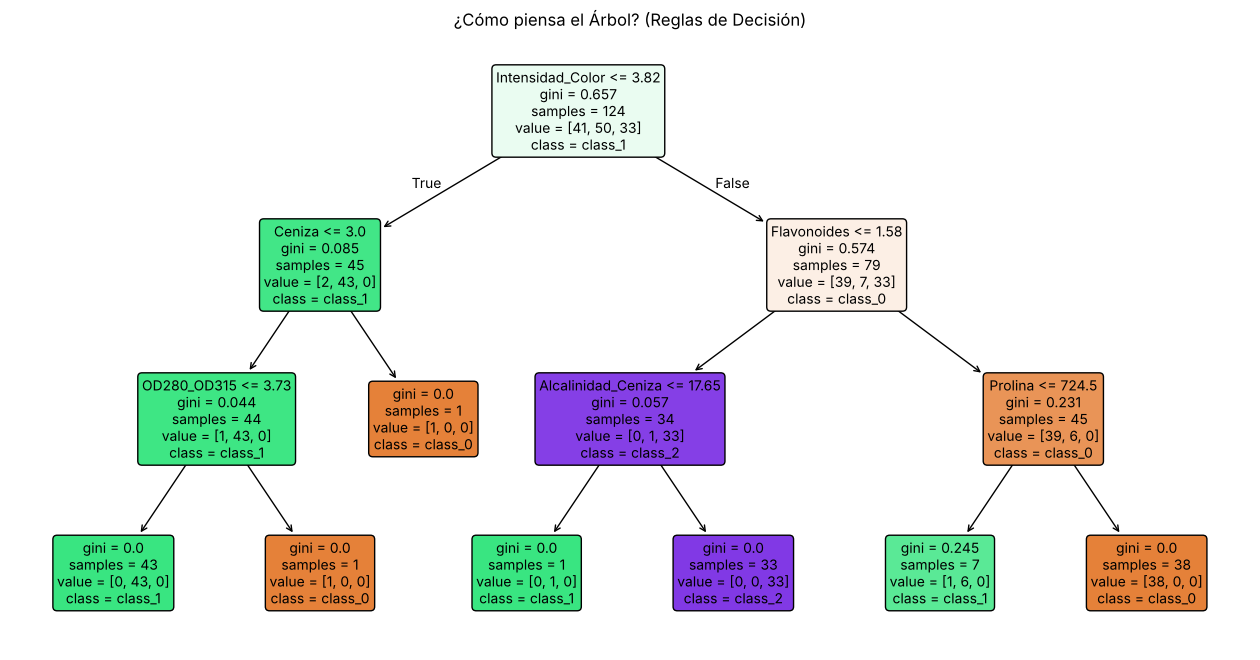

In [9]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(arbol,
          feature_names=X.columns, # Usamos nuestras nuevas columnas en español
          class_names=datos_vino.target_names,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('¿Cómo piensa el Árbol? (Reglas de Decisión)')
plt.show()

---
## **Paso 5: Modelo 3 - Naive Bayes**

**Filosofía:** Probabilidad Pura (Teorema de Bayes).
Se llama "Ingenuo" (*Naive*) porque asume que el nivel de Alcohol no tiene relación matemática con el Magnesio. En la realidad esto es falso, pero asumir esa ingenuidad hace que el cálculo de probabilidades sea **extremadamente rápido**.

In [10]:
from sklearn.naive_bayes import GaussianNB

# 1. Instanciar y Entrenar
bayes = GaussianNB()
bayes.fit(X_train, y_train)

# 2. Predecir y Evaluar
pred_bayes = bayes.predict(X_test)
acc_bayes = accuracy_score(y_test, pred_bayes)
print(f"Exactitud de Naive Bayes: {acc_bayes * 100:.2f}%")

Exactitud de Naive Bayes: 100.00%


---
## **Paso 6: Comparación de Fronteras de Decisión (Visualización de los Datos Reales)**

Para entender verdaderamente cómo funciona cada algoritmo (y para que sea fácil de enseñar a la clase), **reduciremos nuestro dataset a solo 2 columnas** (`Alcohol` y `Flavonoides`) para poder graficarlo en un plano de 2 dimensiones (X e Y).

Esto nos permitirá ver visualmente cómo cada algoritmo "corta" (Frontera de Decisión) la gráfica para clasificar los vinos.

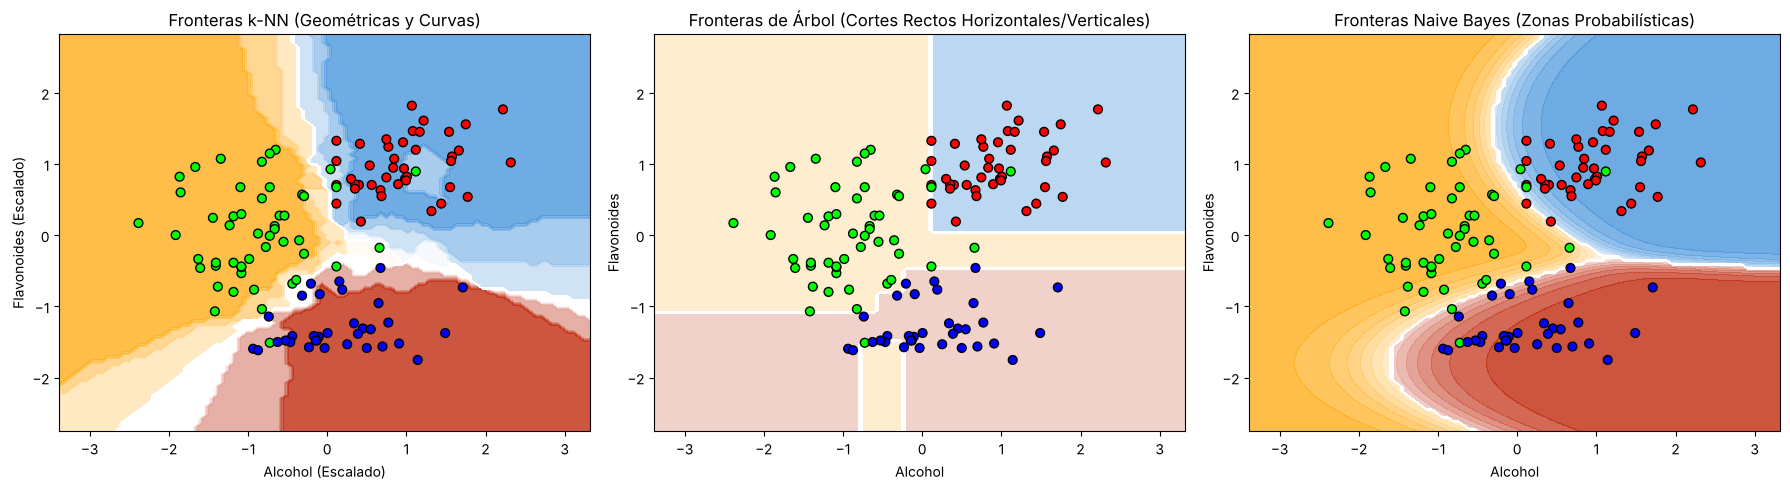

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

# Para poder graficar en 2D, elegimos solo 2 características.
X_2D = X_train[['Alcohol', 'Flavonoides']]

# k-NN sufre si no lo escalamos, así que escalamos estas 2 columnas
scaler_2d = StandardScaler()
X_2D_esc = scaler_2d.fit_transform(X_2D)

# Entrenamos 3 modelos "miniaturas" que solo ven estas 2 columnas
knn_2d = KNeighborsClassifier(n_neighbors=5).fit(X_2D_esc, y_train)
arbol_2d = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_2D_esc, y_train)
bayes_2d = GaussianNB().fit(X_2D_esc, y_train)

# Configuración del gráfico (3 paneles)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

# --- 1. Panel de k-NN ---
DecisionBoundaryDisplay.from_estimator(knn_2d, X_2D_esc, cmap=cmap_light, ax=ax1, alpha=0.8)
ax1.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax1.set_title("Fronteras k-NN (Geométricas y Curvas)")
ax1.set_xlabel('Alcohol (Escalado)')
ax1.set_ylabel('Flavonoides (Escalado)')

# --- 2. Panel de Árbol de Decisión ---
DecisionBoundaryDisplay.from_estimator(arbol_2d, X_2D_esc, cmap=cmap_light, ax=ax2, alpha=0.8)
ax2.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax2.set_title("Fronteras de Árbol (Cortes Rectos Horizontales/Verticales)")
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Flavonoides')

# --- 3. Panel de Naive Bayes ---
DecisionBoundaryDisplay.from_estimator(bayes_2d, X_2D_esc, cmap=cmap_light, ax=ax3, alpha=0.8)
ax3.scatter(X_2D_esc[:, 0], X_2D_esc[:, 1], c=y_train, cmap=cmap_bold, edgecolor='k', s=40)
ax3.set_title("Fronteras Naive Bayes (Zonas Probabilísticas)")
ax3.set_xlabel('Alcohol')
ax3.set_ylabel('Flavonoides')

plt.tight_layout()
plt.show()

Observe las gráficas de arriba junto a sus alumnos:
* **k-NN** genera áreas curvas de decisión como si trazara contornos geográficos intentando rodear a los grupitos.
* **Árbol de Decisión** JAMÁS genera curvas. Todo son cortes perfectamente rectos horizontales y verticales, porque son reglas de "Mayor que" y "Menor que".
* **Naive Bayes** genera zonas amplias y suavizadas dictadas por las campanas de distribución probabilística.

---
## **Paso 7: Comparación de Desempeño y Conclusión de Taller**

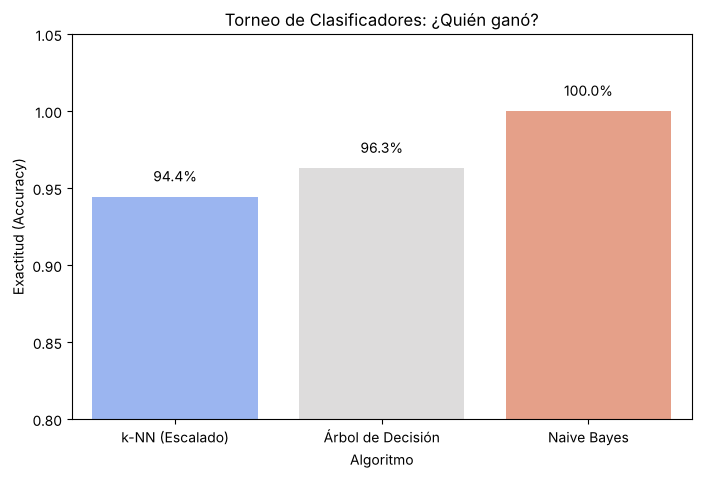

In [12]:
# Crear un DataFrame con los resultados
resultados = pd.DataFrame({
    'Algoritmo': ['k-NN (Escalado)', 'Árbol de Decisión', 'Naive Bayes'],
    'Exactitud (Accuracy)': [acc_knn, acc_arbol, acc_bayes]
})

# Graficar comparativa
plt.figure(figsize=(8,5))
sns.barplot(x='Algoritmo', y='Exactitud (Accuracy)', data=resultados, palette='coolwarm')
plt.title('Torneo de Clasificadores: ¿Quién ganó?')
plt.ylim(0.8, 1.05) # Enfocar el gráfico en la parte alta para notar las diferencias

# Agregar etiquetas de porcentaje en las barras
for index, row in resultados.iterrows():
    plt.text(index, row['Exactitud (Accuracy)'] + 0.01, f"{row['Exactitud (Accuracy)']*100:.1f}%", color='black', ha="center")

plt.show()

### **Conclusión del Docente:**
En este dataset en particular, los resultados pueden ser muy parejos. Sin embargo, en el mundo real:
* Si el cliente necesita saber **POR QUÉ** se tomó una decisión (ej. Auditoría Médica o Legal), el **Árbol de Decisión** es el único que da explicaciones visuales.
* Si el dataset fuera de 5 millones de correos electrónicos (texto gigante), **k-NN** colapsaría y **Naive Bayes** lo resolvería en segundos.
* Si las fronteras de separación son muy complejas y curvas, **k-NN** suele adaptarse maravillosamente.

---
# **PARTE 2: Una tercera columna representativa y comparación de pares**

En el Paso 6 solo vimos el par **(Alcohol, Flavonoides)**. Ahora:

1. Elegimos con criterios estadísticos una **3ª columna representativa**.
2. Repetimos el método (k-NN, Árbol, Naive Bayes + fronteras de decisión) con **tres pares**:
   * Par A: `Alcohol` + `Flavonoides` (el original)
   * Par B: `Alcohol` + 3ª columna
   * Par C: `Flavonoides` + 3ª columna
3. Comparamos con **mapas de calor** y sacamos conclusiones.

## **Paso 8: ¿Cuál es la mejor 3ª columna?**

Usamos tres criterios sobre los datos de entrenamiento (para no hacer trampa con el test): **ANOVA F**, **Información Mutua** e **importancia en un Árbol de Decisión**. Además miramos la **redundancia**: una buena 3ª columna debe aportar información *distinta* a Alcohol y Flavonoides.

In [13]:
from sklearn.feature_selection import f_classif, mutual_info_classif

F, _ = f_classif(X_train, y_train)
MI = mutual_info_classif(X_train, y_train, random_state=42)
IMP = DecisionTreeClassifier(random_state=42).fit(X_train, y_train).feature_importances_

ranking = pd.DataFrame({'ANOVA_F': F, 'Info_Mutua': MI, 'Imp_Arbol': IMP}, index=X.columns)
ranking['Rank_promedio'] = ranking.rank(ascending=False).mean(axis=1)
ranking = ranking.sort_values('Rank_promedio')
display(ranking.round(3))

# Redundancia de los candidatos con las 2 columnas ya usadas
corr_train = X_train.corr()
candidatas = ['Prolina', 'OD280_OD315', 'Intensidad_Color']
tabla = ranking.loc[candidatas, ['ANOVA_F', 'Info_Mutua', 'Imp_Arbol']].copy()
tabla['|corr| con Alcohol'] = [abs(corr_train.loc[c, 'Alcohol']) for c in candidatas]
tabla['|corr| con Flavonoides'] = [abs(corr_train.loc[c, 'Flavonoides']) for c in candidatas]
print('Candidatas a 3ª columna:')
display(tabla.round(3))

,ANOVA_F,Info_Mutua,Imp_Arbol,Rank_promedio
Flavonoides,187.686,0.671,0.405,1.000
Prolina,149.434,0.515,0.107,2.667
Intensidad_Color,83.979,0.603,0.397,3.000
OD280_OD315,126.619,0.512,0.024,3.667
Alcohol,100.346,0.501,0.000,6.500
Matiz,72.267,0.419,0.000,7.500
Alcalinidad_Ceniza,26.053,0.211,0.024,8.000
Acido_Malico,22.583,0.317,0.021,8.000
Fenoles_Totales,59.256,0.405,0.000,8.167
Proantocianidinas,19.980,0.281,0.000,9.833


Candidatas a 3ª columna:


,ANOVA_F,Info_Mutua,Imp_Arbol,|corr| con Alcohol,|corr| con Flavonoides
Prolina,149.434,0.515,0.107,0.661,0.502
OD280_OD315,126.619,0.512,0.024,0.096,0.775
Intensidad_Color,83.979,0.603,0.397,0.546,0.168


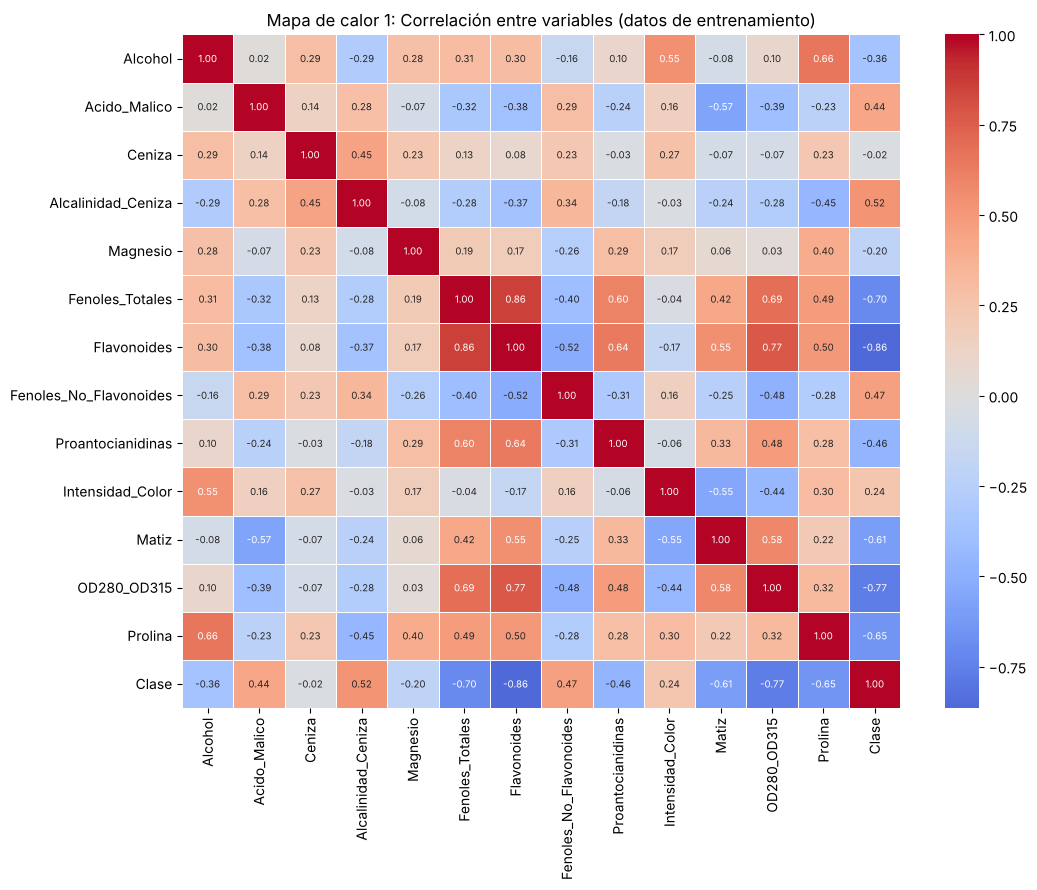

In [14]:
# MAPA DE CALOR 1: correlación entre las 13 variables + clase
datos_corr = X_train.copy()
datos_corr['Clase'] = y_train.values
plt.figure(figsize=(11, 9))
sns.heatmap(datos_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5, annot_kws={'size': 7})
plt.title('Mapa de calor 1: Correlación entre variables (datos de entrenamiento)')
plt.tight_layout(); plt.show()

**Decisión:** elegimos **`Intensidad_Color`** como 3ª columna:
* Es de las más informativas en los tres criterios (sobre todo Información Mutua e importancia en el árbol).
* Es poco redundante con `Flavonoides` (correlación baja), así que aporta una dimensión nueva.
* `Prolina` es buena por ANOVA, pero está muy correlacionada con `Alcohol`, por lo que repetiría información en el Par B.

## **Paso 9: Los tres pares, los tres algoritmos**

Entrenamos cada algoritmo con cada par. Para que la comparación sea justa usamos el mismo pipeline (con `StandardScaler`, que no afecta al árbol ni a Naive Bayes pero es obligatorio para k-NN). Medimos la exactitud en el **test** y también con **validación cruzada de 5 folds** sobre los 178 vinos, porque 54 muestras de test son pocas.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

TERCERA = 'Intensidad_Color'
pares = {
    'A: Alcohol + Flavonoides': ['Alcohol', 'Flavonoides'],
    f'B: Alcohol + {TERCERA}': ['Alcohol', TERCERA],
    f'C: Flavonoides + {TERCERA}': ['Flavonoides', TERCERA],
}
def modelos():
    return {
        'k-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        'Árbol': make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=3, random_state=42)),
        'Naive Bayes': make_pipeline(StandardScaler(), GaussianNB()),
    }
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

acc_test, acc_cv, entrenados = {}, {}, {}
for par, cols in pares.items():
    for nombre, mod in modelos().items():
        mod.fit(X_train[cols], y_train)
        entrenados[(par, nombre)] = mod
        acc_test[(par, nombre)] = accuracy_score(y_test, mod.predict(X_test[cols]))
        acc_cv[(par, nombre)] = cross_val_score(modelos()[nombre], X[cols], y, cv=cv).mean()

# Referencia: los 3 modelos con las 3 columnas juntas (no se puede graficar en 2D)
tres = ['Alcohol', 'Flavonoides', TERCERA]
ref = {}
for nombre, mod in modelos().items():
    mod.fit(X_train[tres], y_train)
    ref[nombre] = (accuracy_score(y_test, mod.predict(X_test[tres])),
                   cross_val_score(modelos()[nombre], X[tres], y, cv=cv).mean())
print('Entrenados', len(entrenados), 'modelos.')

Entrenados 9 modelos.


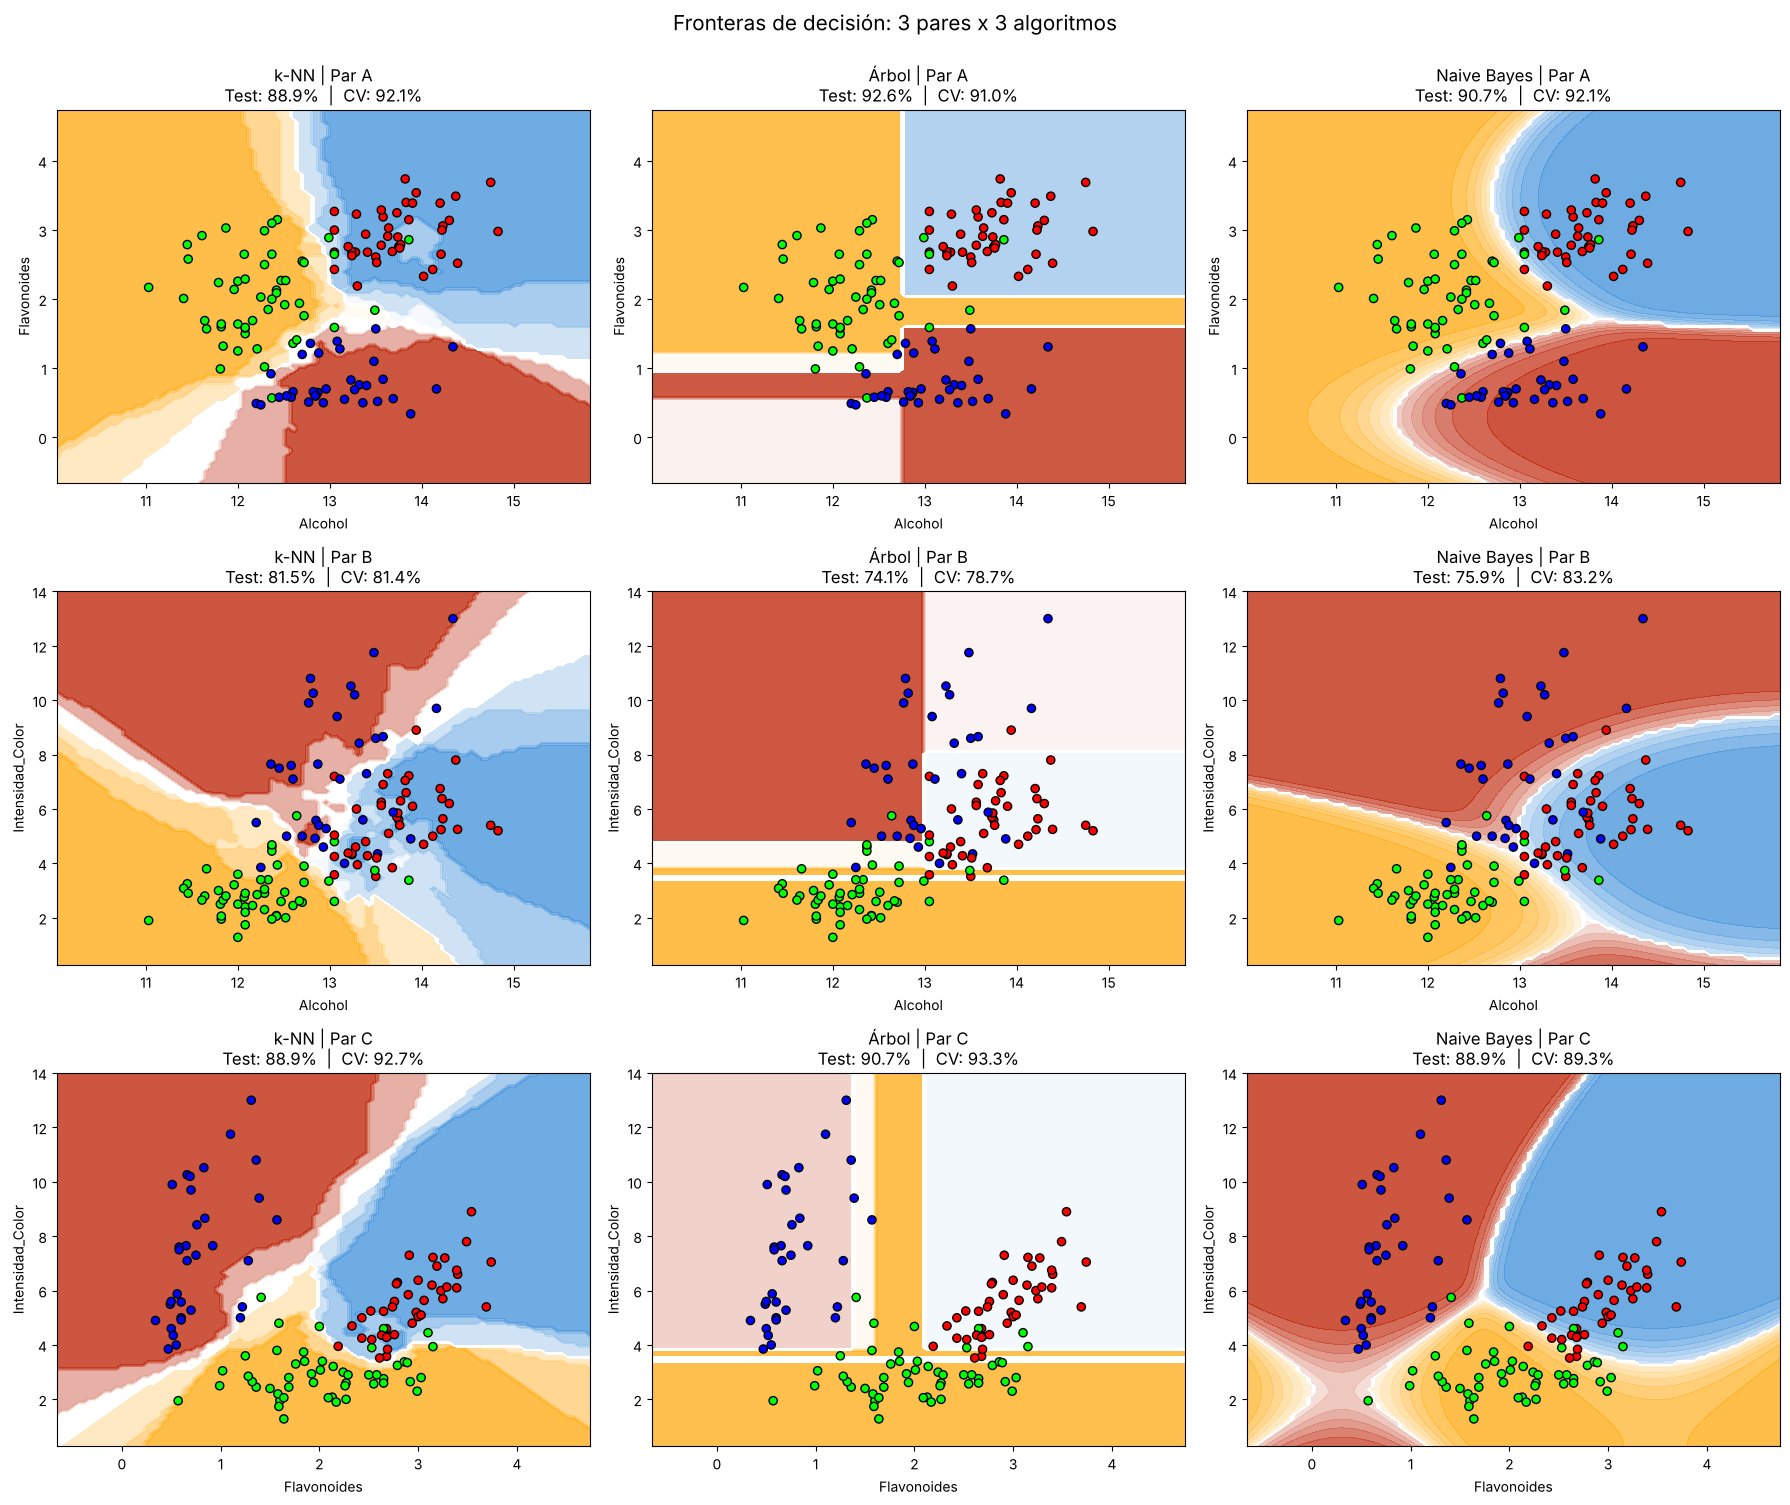

In [16]:
# FRONTERAS DE DECISIÓN: filas = pares, columnas = algoritmos
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
for i, (par, cols) in enumerate(pares.items()):
    for j, nombre in enumerate(['k-NN', 'Árbol', 'Naive Bayes']):
        ax = axes[i, j]
        mod = entrenados[(par, nombre)]
        DecisionBoundaryDisplay.from_estimator(mod, X_train[cols], cmap=cmap_light, ax=ax, alpha=0.8,
                                               xlabel=cols[0], ylabel=cols[1])
        ax.scatter(X_train[cols[0]], X_train[cols[1]], c=y_train, cmap=cmap_bold, edgecolor='k', s=35)
        ax.set_title(f'{nombre} | Par {par[0]}\nTest: {acc_test[(par, nombre)]*100:.1f}%  |  CV: {acc_cv[(par, nombre)]*100:.1f}%')
plt.suptitle('Fronteras de decisión: 3 pares x 3 algoritmos', fontsize=15, y=1.00)
plt.tight_layout(); plt.show()

## **Paso 10: Mapas de calor de desempeño**

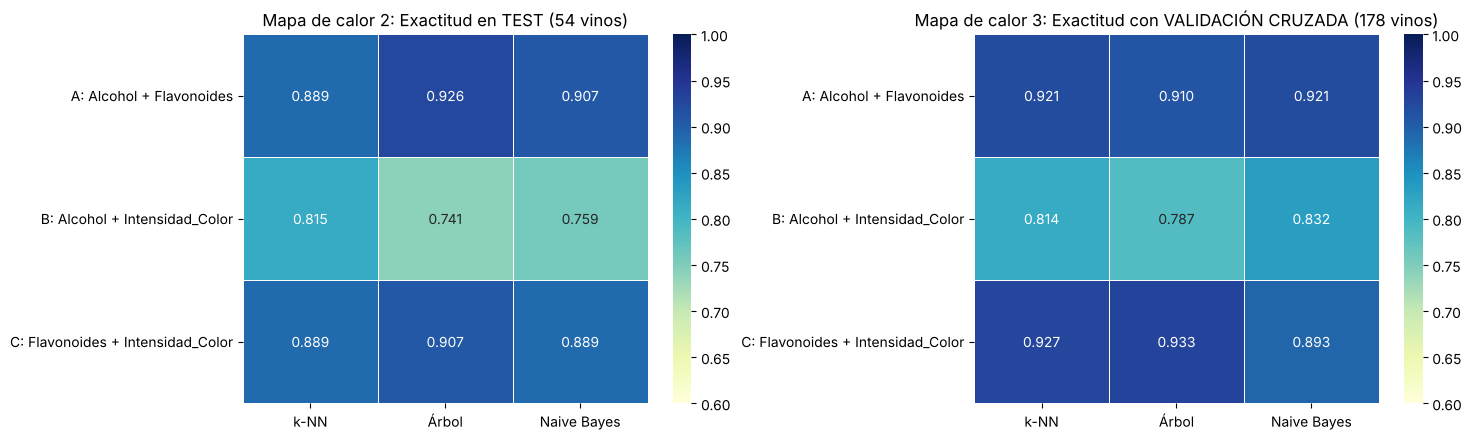

Referencia con las 3 columnas juntas (Alcohol + Flavonoides + Intensidad_Color):


,Test,CV 5-folds
k-NN,0.926,0.944
Árbol,0.944,0.933
Naive Bayes,0.907,0.938


In [17]:
filas = list(pares.keys())
cols_m = ['k-NN', 'Árbol', 'Naive Bayes']
H_test = pd.DataFrame([[acc_test[(p, m)] for m in cols_m] for p in filas], index=filas, columns=cols_m)
H_cv = pd.DataFrame([[acc_cv[(p, m)] for m in cols_m] for p in filas], index=filas, columns=cols_m)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, H, t in [(axes[0], H_test, 'Mapa de calor 2: Exactitud en TEST (54 vinos)'),
                 (axes[1], H_cv, 'Mapa de calor 3: Exactitud con VALIDACIÓN CRUZADA (178 vinos)')]:
    sns.heatmap(H, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0.6, vmax=1.0, linewidths=.5, ax=ax)
    ax.set_title(t); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print('Referencia con las 3 columnas juntas (Alcohol + Flavonoides + %s):' % TERCERA)
display(pd.DataFrame(ref, index=['Test', 'CV 5-folds']).T.round(3))

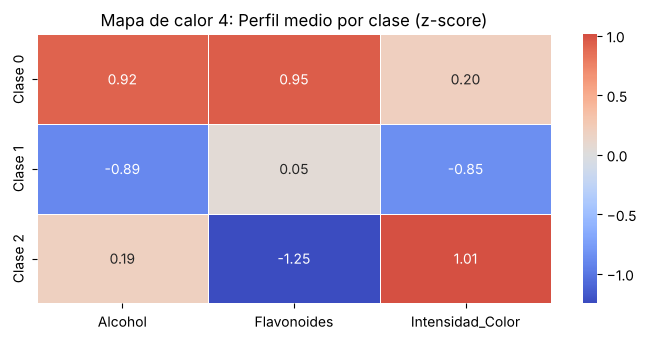

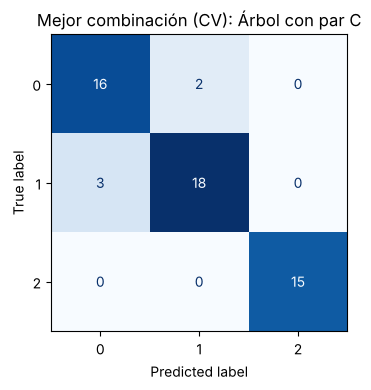

Mejor combinación por CV: ('C: Flavonoides + Intensidad_Color', 'Árbol') 0.933


In [18]:
# MAPA DE CALOR 4: ¿cómo se distingue cada clase en las 3 columnas? (media estandarizada por clase)
z = (X[tres] - X[tres].mean()) / X[tres].std()
medias = z.groupby(y.values).mean()
medias.index = ['Clase 0', 'Clase 1', 'Clase 2']
plt.figure(figsize=(7, 3.5))
sns.heatmap(medias, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Mapa de calor 4: Perfil medio por clase (z-score)')
plt.tight_layout(); plt.show()

# Y la matriz de confusión del mejor modelo 2D en test, para ver qué clases se mezclan
from sklearn.metrics import ConfusionMatrixDisplay
mejor = max(acc_cv, key=acc_cv.get)
cols_mejor = pares[mejor[0]]
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_estimator(entrenados[mejor], X_test[cols_mejor], y_test, cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Mejor combinación (CV): {mejor[1]} con par {mejor[0][0]}')
plt.tight_layout(); plt.show()
print('Mejor combinación por CV:', mejor, round(acc_cv[mejor], 3))

## **Paso 11: Conclusiones**

**1. Elección de la 3ª columna.** `Intensidad_Color` fue la más complementaria: 3ª en el ranking promedio (muy alta Información Mutua = 0.60 e importancia en el árbol = 0.40) y con correlación de solo 0.17 con `Flavonoides`. `Prolina` y `OD280_OD315` puntúan alto en ANOVA, pero están muy correlacionadas con Alcohol (0.66) o con Flavonoides (0.78), es decir, repiten información.

**2. Comparación de pares (exactitud, test / validación cruzada).**

| Par | k-NN | Árbol | Naive Bayes |
|---|---|---|---|
| A: Alcohol + Flavonoides | 88.9% / 92.1% | 92.6% / 91.0% | 90.7% / 92.1% |
| B: Alcohol + Intensidad_Color | 81.5% / 81.4% | 74.1% / 78.7% | 75.9% / 83.2% |
| C: Flavonoides + Intensidad_Color | 88.9% / 92.7% | 90.7% / 93.3% | 88.9% / 89.3% |

* **Los pares con Flavonoides (A y C) ganan claramente** (~89-93%) frente al par B (~74-83%). Flavonoides es la variable que más separa las clases; sin ella se pierde ~10 puntos.
* **A y C son prácticamente equivalentes**: con 54 muestras de test, una diferencia de 1-2 vinos es ruido. En validación cruzada, C (Flavonoides + Intensidad_Color) es ligeramente mejor con k-NN y Árbol; A con Naive Bayes.
* **El par B falla porque Alcohol e Intensidad_Color están correlacionadas (0.55)** y las clases 1 y 2 se solapan en ese plano: las fronteras se ven mezcladas (mapa de calor 4 y fronteras).

**3. Mapas de calor.** El de correlación muestra que Flavonoides y Intensidad_Color son casi independientes (buen par). El de perfil por clase muestra por qué funcionan: la clase 0 tiene Alcohol alto, la clase 1 Intensidad_Color baja y la clase 2 Flavonoides bajos e Intensidad alta; cada variable aísla una clase distinta.

**4. Algoritmos.** Ninguno gana siempre: depende del par. El Árbol es el más sensible a una mala pareja (74% en B), y k-NN el más estable. Usar las 3 columnas juntas (~93-94% CV) no mejora a los mejores pares de 2D, y las 13 columnas del Paso 5 (94-100%) siguen siendo superiores: las 2D sirven para *entender e interpretar*, no para máxima precisión.

**5. Cautela.** Con solo 54 muestras de test, las diferencias pequeñas no son concluyentes; por eso se añadió la validación cruzada.